In [23]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score
from rdkit import Chem
from rdkit.Chem import MACCSkeys

# 1. Load the real EGFR dataset, but grab just the first 100 rows to keep it fast
df = pd.read_csv("EGFR_compounds_lipinski.csv", index_col=0).head(100)

df

,molecule_chembl_id,IC50,units,smiles,pIC50,molecular_weight,n_hba,n_hbd,logp,ro5_fulfilled
0,CHEMBL304271,0.45,nM,CCN(CC)CC(O)CNC(=O)c1cc(C)c(/C=C2\C(=O)Nc3ncnc...,9.346787,541.200444,7,5,3.57442,True
1,CHEMBL264382,1.10,nM,Cc1cc(C(=O)NCCN2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncn...,8.958607,602.275387,7,4,4.41442,True
2,CHEMBL69358,1.20,nM,CCN(CC)CCNC(=O)c1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4...,8.920819,511.189879,6,4,4.21352,True
3,CHEMBL67003,1.80,nM,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,8.744727,560.228437,7,3,4.21982,True
4,CHEMBL305246,2.80,nM,Cc1cc(C(=O)N2CCN(C)CC2)[nH]c1/C=C1\C(=O)Nc2ncn...,8.552842,495.158579,6,3,3.52952,True
...,...,...,...,...,...,...,...,...,...,...
95,CHEMBL309866,1300000.00,nM,N#C/C(=C\c1ccc([N+](=O)[O-])cc1)C(=O)O,2.886057,218.032757,4,1,1.58638,True
96,CHEMBL77381,1360000.00,nM,N#C/C(=C/c1ccc[nH]1)C(=O)O,2.866461,162.042927,2,2,1.00628,True
97,CHEMBL308339,1400000.00,nM,N#CC(C#N)=C1C(=O)NC(=O)NC1=O,2.853872,190.012690,5,2,-1.30384,True
98,CHEMBL308133,1500000.00,nM,O=C(O)C(=Cc1ccc(O)cc1)C(=O)O,2.823909,208.037173,3,3,0.94480,True


EGFR Common Core SMARTS: [#7]-[#6]:,-[#6]:,-[#6]1:[#6](:[#7]:[#6]:[#7]:[#6]:1)-[#7]-[#6]1:[#6]:[#6]:[#6]:[#6]:[#6]:1
The shared EGFR scaffold has 16 atoms.


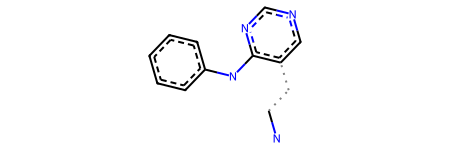

In [27]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import rdFMCS

# Assuming `df` is your DataFrame containing EGFR molecules from ChEMBL
# and your SMILES column is named 'smiles' (or 'canonical_smiles')

# 1. Convert a subset of your EGFR SMILES into RDKit molecules
# (Taking the first 10 or 20 for speed, since MCS can slow down on massive sets)
mols = [Chem.MolFromSmiles(s) for s in df['smiles'].head(15).dropna()]

# 2. Run FindMCS on your EGFR dataset
result = rdFMCS.FindMCS(mols)

print("EGFR Common Core SMARTS:", result.smartsString)

# 3. Convert to a molecule object to see the size of the shared core
egfr_core = Chem.MolFromSmarts(result.smartsString)
print(f"The shared EGFR scaffold has {egfr_core.GetNumAtoms()} atoms.")
egfr_core

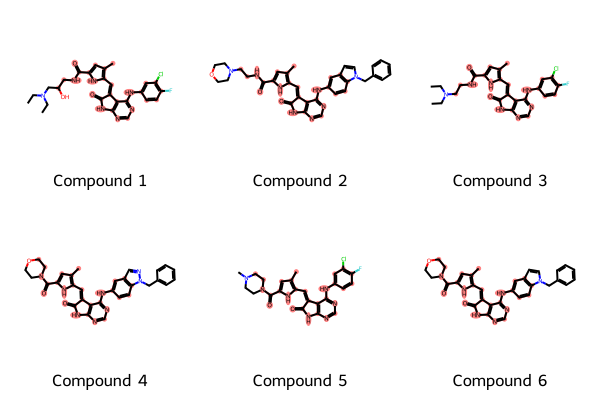

In [25]:
from rdkit import Chem
from rdkit.Chem import rdFMCS
from rdkit.Chem import Draw

# 1. Grab a small subset of your EGFR DataFrame (e.g., first 6 rows)
# Always subset for visualization so the grid doesn't get cluttered
subset_df = df.head(6).dropna(subset=['smiles'])
mols = [Chem.MolFromSmiles(s) for s in subset_df['smiles']]

# 2. Find the MCS and convert it to a molecule object
result = rdFMCS.FindMCS(mols)
common_core = Chem.MolFromSmarts(result.smartsString)

# 3. Extract matching atom indices for each EGFR molecule
highlight_lists = [mol.GetSubstructMatch(common_core) for mol in mols]

# 4. Draw them side-by-side with the shared core highlighted
grid_img = Draw.MolsToGridImage(
    mols,
    legends=[f"Compound {i+1}" for i in range(len(mols))],
    highlightAtomLists=highlight_lists
)

# In a Jupyter notebook, executing `grid_img` renders the image
grid_img

MCS SMARTS: [#6]1:[#6]:[#6]:[#6]:[#6]:[#6]:1
Atom count in common core: 6


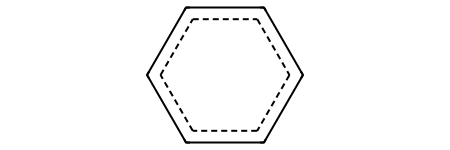

In [14]:
from rdkit import Chem
from rdkit.Chem import rdFMCS

# 1. Define a few molecules via SMILES (Phenol, Aniline, Toluene)
smiles_list = ["c1ccccc1O", "c1ccccc1N", "c1ccccc1C"]
mols = [Chem.MolFromSmiles(s) for s in smiles_list]

# 2. Run the FindMCS function
result = rdFMCS.FindMCS(mols)

# 3. See what the shared core looks like as a SMARTS string
print("MCS SMARTS:", result.smartsString)

# Convert it back into an RDKit molecule object if you want to use it further
common_core = Chem.MolFromSmarts(result.smartsString)
print("Atom count in common core:", common_core.GetNumAtoms())
common_core

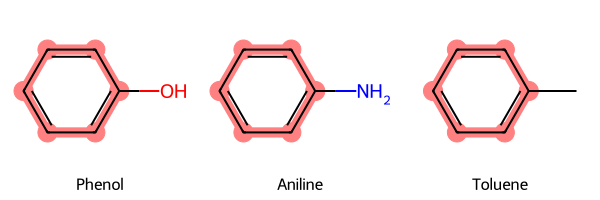

In [19]:
from rdkit import Chem
from rdkit.Chem import rdFMCS
from rdkit.Chem import Draw

# 1. Define molecules and find the MCS
smiles_list = ["c1ccccc1O", "c1ccccc1N", "c1ccccc1C"]
mols = [Chem.MolFromSmiles(s) for s in smiles_list]

result = rdFMCS.FindMCS(mols)
common_core = Chem.MolFromSmarts(result.smartsString)

# 2. Extract matching atom indices for each molecule
highlight_lists = [mol.GetSubstructMatch(common_core) for mol in mols]

# 3. Draw the molecules side-by-side with the common core highlighted in color
grid_img = Draw.MolsToGridImage(
    mols,
    legends=["Phenol", "Aniline", "Toluene"],
    highlightAtomLists=highlight_lists
)

# In a Jupyter notebook, just type `grid_img` to display it!
grid_img